# Vertebra segmentation from a frontal spine X-ray

Group term project (3 members). I designed the vertebra-splitting algorithm (Part 3). Input: a frontal full-spine X-ray. Output: one cropped image per vertebra, labelled from the sacrum up to C1. Only classical image processing is used, with no trained model, so every step can be inspected.

1. **Pre-processing:** gamma correction, CLAHE contrast enhancement and edge enhancement make the bones stand out.
2. **Spine isolation:** the brightest region in each horizontal strip of the central part of the image is kept, which leaves only the spine.
3. **Vertebra splitting:** the row sums of the isolated spine have a minimum between neighbouring vertebrae. Those minima are the cut points.

The README of this folder lists the parameters and the limitations.


# Part 1: Pre-processing

Gamma correction (gamma 4.5), then CLAHE (clip limit 3, 8 x 8 tiles). Sobel and Canny edge maps are combined and blended back into the image (weights 0.7 and 0.3). The panels below show each step, including a JET pseudocolor view that makes the bone structure easier to see.


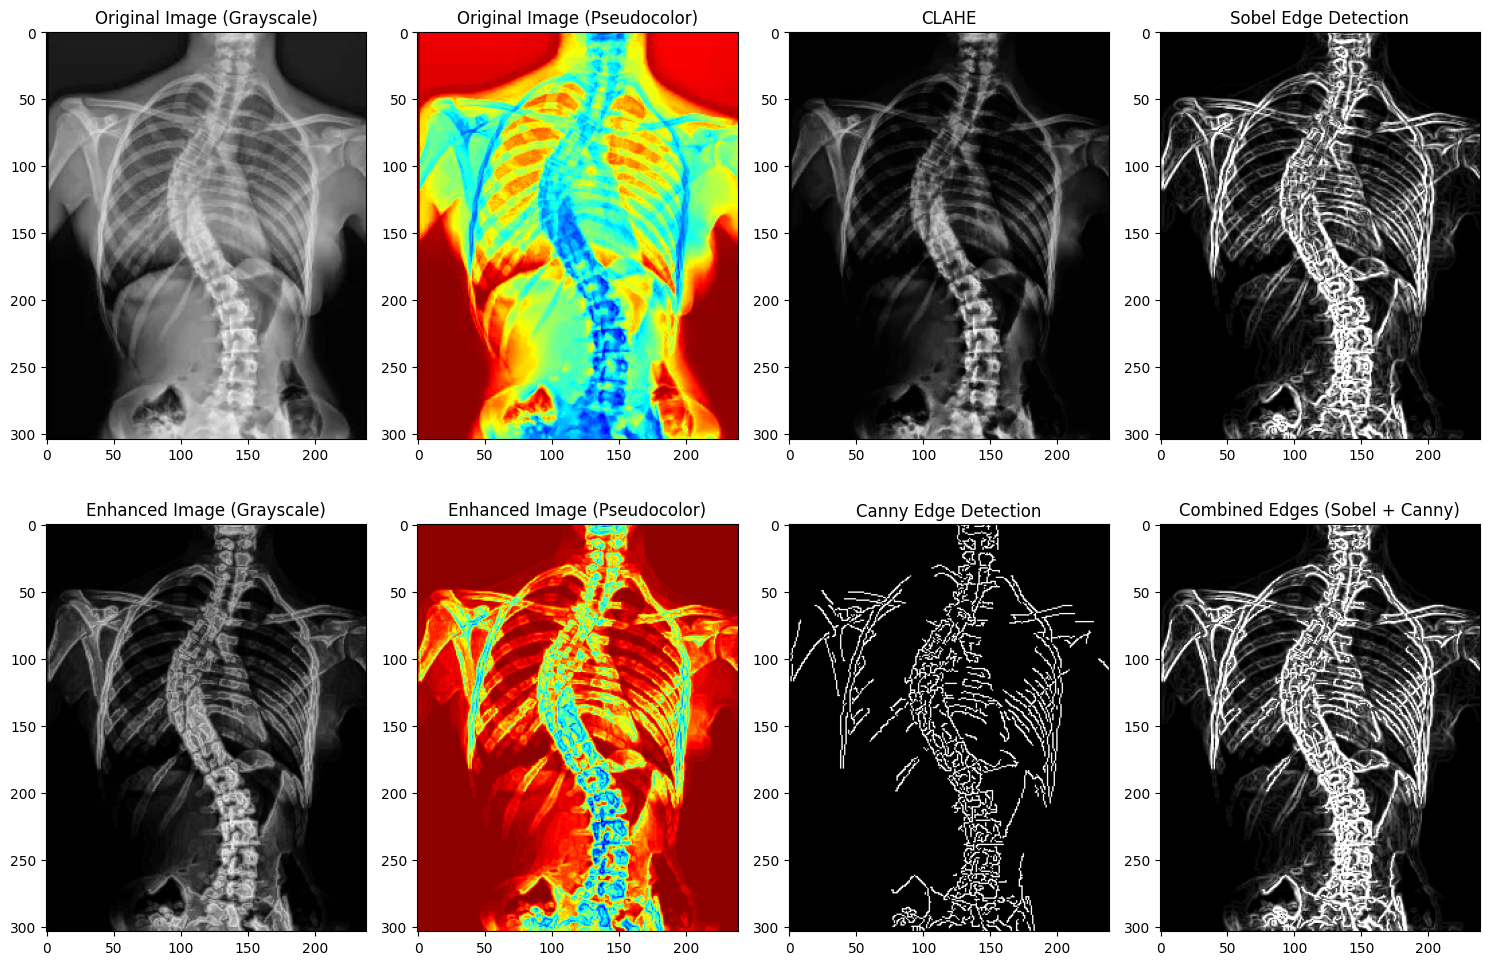

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def load_image(image_path):
    """Load the image in grayscale."""
    return cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

def apply_gamma_correction(image, gamma):
    """Apply gamma correction to the image."""
    image_float = np.float32(image) / 255.0  # Normalize the pixel values to [0, 1]
    gamma_corrected = np.power(image_float, gamma)
    return np.uint8(gamma_corrected * 255)

def apply_clahe(image):
    """Apply CLAHE (Contrast Limited Adaptive Histogram Equalization) to enhance contrast."""
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    return clahe.apply(image)

def detect_edges(image, method='sobel'):
    """Detect edges using Sobel or Canny method."""
    if method == 'sobel':
        sobel_x = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)  # Horizontal gradient
        sobel_y = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)  # Vertical gradient
        edges = cv2.magnitude(sobel_x, sobel_y)
        return cv2.convertScaleAbs(edges)
    elif method == 'canny':
        return cv2.Canny(image, 150, 255)

def enhance_image(image, edges):
    """Enhance the image by adding edges back to the original."""
    return cv2.addWeighted(image, 0.7, edges, 0.3, 0)

def apply_pseudocolor(image):
    """Apply pseudocolor (JET colormap) to the image."""
    return cv2.applyColorMap(image, cv2.COLORMAP_JET)

def plot_images(images, titles, layout=(2, 4)):
    """Plot images with given titles in a grid layout."""
    plt.figure(figsize=(15, 10))
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(*layout, i + 1)
        plt.imshow(img, cmap='gray' if len(img.shape) == 2 else None)
        plt.title(title)
    plt.tight_layout()
    plt.show()

def main(image_path, gamma=4.5):
    """Main function to execute the image processing pipeline."""

    # Step 1: Load Image
    image = load_image(image_path)

    # Step 2: Apply Gamma Correction
    gamma_corrected = apply_gamma_correction(image, gamma)

    # Step 3: Apply CLAHE
    image_clahe = apply_clahe(gamma_corrected)

    # Step 4: Edge Detection (Sobel and Canny)
    sobel_edges = detect_edges(image_clahe, method='sobel')
    canny_edges = detect_edges(image_clahe, method='canny')

    # Step 5: Combine Edges
    combined_edges = cv2.bitwise_or(sobel_edges, canny_edges)

    # Step 6: Enhance Image with Edges
    enhanced_image = enhance_image(image_clahe, combined_edges)

    # Step 7: Apply Pseudocolor
    pseudocolor_original = apply_pseudocolor(image)
    pseudocolor_enhanced = apply_pseudocolor(enhanced_image)

    # Step 8: Save enhanced image
    cv2.imwrite('enhanced_image.jpeg', enhanced_image)

    # Step 9: Display Results
    images = [image, pseudocolor_original, image_clahe, sobel_edges, enhanced_image, pseudocolor_enhanced, canny_edges, combined_edges]
    titles = ['Original Image (Grayscale)', 'Original Image (Pseudocolor)', 'CLAHE', 'Sobel Edge Detection',
              'Enhanced Image (Grayscale)', 'Enhanced Image (Pseudocolor)', 'Canny Edge Detection', 'Combined Edges (Sobel + Canny)']

    plot_images(images, titles)

# Run the main function with the specified image path and gamma value
image_path = '/content/4.jpeg'  # Change to the correct path
main(image_path, gamma=4.5)


# Part 2 : Spine-Segmentation

Algorithm:

1. Split the image: divide the image into 25 small strips along its height.

2. Find the brightest region: compute the mean brightness in each strip

3. and locate the region with the highest brightness (usually the bone).

4. Create a mask: build a mask that keeps only the brightest region (the spine)
and sets everything else to black.

5. Combine the results: insert the filtered parts back into a new background image.

6. Display: show the resulting image, which contains only the cropped spine.

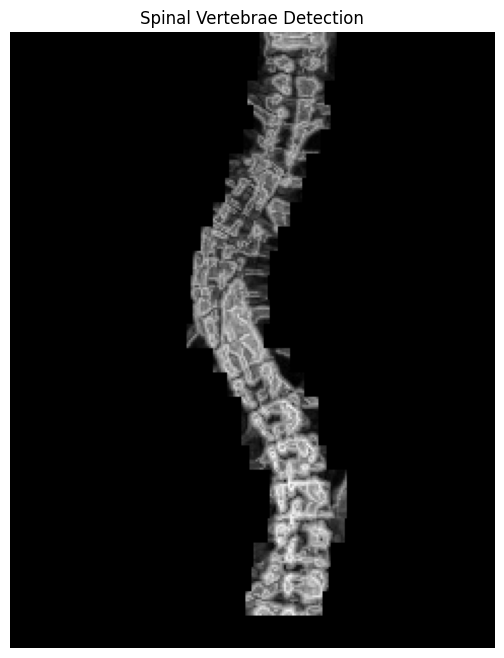

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Main function
def spine_segments(image_path):
    # Read the X-ray image and adjust contrast with CLAHE
    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    # Open the image with PIL to split it into parts
    image = Image.fromarray(image)
    width, height = image.size
    new_width = width // 2.5
    part_height = height // 25

    # Starting position for cropping
    left = (width - new_width) // 2
    right = left + new_width

    modified_parts = []

    # Cut the image and find the brightest part
    for i in range(25):
        if i < 24:
            top = i * part_height  # Set top to advance one strip at a time
            bottom = top + part_height  # The bottom of each strip is top + part_height

        # Check that bottom does not go beyond the image
        if bottom > height:
            bottom = height

        # Cut out the wanted part of the image
        part = image.crop((left, top, right, bottom))
        part_array = np.array(part)

        # Find the brightest part
        max_intensity = -1
        best_x_start = 0
        mask_width = int(2 / 5 * part_array.shape[1])  # Width of the mask

        # Find the brightest region in each strip
        for x in range(0, part_array.shape[1] - mask_width):
            subpart = part_array[:, x:x + mask_width]
            avg_intensity = np.mean(subpart)
            if avg_intensity > max_intensity:
                max_intensity = avg_intensity
                best_x_start = x

        # Create a mask for the brightest region
        mask = np.zeros_like(part_array)
        mask[:, best_x_start:best_x_start + mask_width] = part_array[:, best_x_start:best_x_start + mask_width]
        part_array[mask == 0] = 0  # Set everything outside the frame to black

        # Store the result
        modified_parts.append((part_array, best_x_start, mask_width, top, bottom))

    # Create a black background image
    final_image = np.zeros_like(image)

    # Insert the wanted parts into final_image
    for part, x_start, mask_width, top, bottom in modified_parts:
        rect_left = int(left + x_start)
        rect_top = int(top)
        rect_right = int(rect_left + mask_width)
        rect_bottom = int(bottom)

        # Check that rect_left, rect_top, rect_right, rect_bottom stay within final_image
        rect_left = max(0, rect_left)
        rect_top = max(0, rect_top)
        rect_right = min(final_image.shape[1], rect_right)
        rect_bottom = min(final_image.shape[0], rect_bottom)

        # Resize the part so it fits the target area in final_image
        part_resized = cv2.resize(part[:, x_start:x_start + mask_width],
                                  (rect_right - rect_left, rect_bottom - rect_top))

        # Insert the part with its original brightness into final_image
        if rect_left < rect_right and rect_top < rect_bottom:
            final_image[rect_top:rect_bottom, rect_left:rect_right] = part_resized

    # Show the final image
    plt.figure(figsize=(8, 8))
    plt.imshow(final_image, cmap='gray')
    plt.axis('off')
    plt.title('Spinal Vertebrae Detection')
    plt.show()
    cv2.imwrite("/content/Spine_Segments.jpeg", final_image)

# Usage
image_path = '/content/enhanced_image.jpeg'  # Change the path to where your image is stored
spine_segments(image_path)


# Part 3 : Vertebral-Segment

Algorithm:

1. Set the left and right edges of the image to 0 to remove regions of no interest.

2. Compute the sum of the values in each row.

3. Apply a moving average to smooth the data.

4. Find the local minima in the smoothed data.

5. Find the minimum of the row sums that is closest to each local minimum of the smoothed data.

6. Use these points as the cut points that separate the vertebrae.

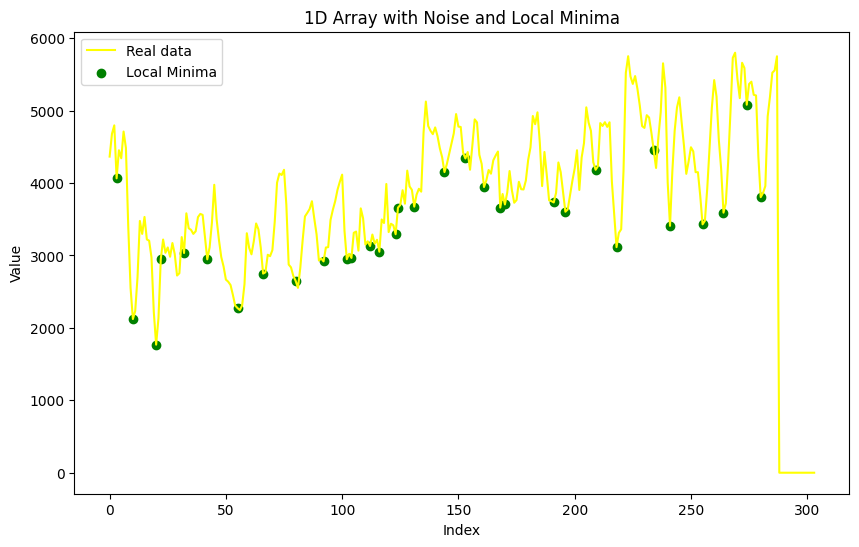

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_path = '/content/Spine_Segments.jpeg'  # Change the path to where the image is stored
spine = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

height, width = spine.shape
start = width/2.5
spine[:, :int(start*0.75)] = 0
spine[:, int(width - start*0.75):] = 0

row_sums = np.sum(spine, axis=1)

def moving_average(arr, window_size):
    return np.convolve(arr, np.ones(window_size)/window_size, mode='valid')

smooth_window = int(height/50)
smoothed_data = moving_average(row_sums, smooth_window)

def find_local_minimum(data):
    """Indices of the local minima of a 1D array."""
    return np.where(np.r_[True, data[1:] < data[:-1]] & np.r_[data[:-1] < data[1:], True])[0]

def find_minima_near_indices(arr, indices, max_distance):
    """For each index, the position of the lowest value of arr within max_distance of it."""
    result_indices = []

    for idx in indices:
        start_idx = max(0, idx - max_distance)
        end_idx = min(len(arr), idx + max_distance + 1)
        ans = start_idx
        for local_idx in range(start_idx, end_idx):
            if arr[local_idx] < arr[ans]:
                ans = local_idx
        result_indices.append(ans)

    return np.unique(np.array(result_indices))

local_min_indices = find_local_minimum(smoothed_data)
cut_points = find_minima_near_indices(row_sums, local_min_indices, int(height/100))

# Plot the row sums and the cut points
plt.figure(figsize=(10, 6))
plt.plot(row_sums, label='Real data', color='yellow')
plt.scatter(cut_points, row_sums[cut_points], color='green', label='Local Minima')
plt.title('Row sums and local minima')
plt.xlabel('Index')
plt.ylabel('Value')
plt.legend()
plt.show()


Algorithm:

1. Reverse the computed cut points, because detection goes from the lower vertebrae up to the top (checked with a doctor).

2. Crop the image, convert each part to an array and store it.

3. Save and display the cropped images.

**Note:** The cervical vertebrae are close together and hard to separate in a frontal view because the bones can overlap.

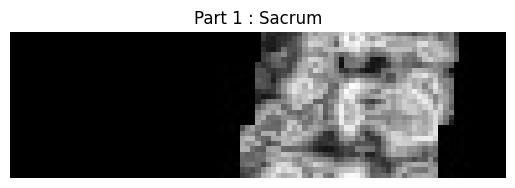

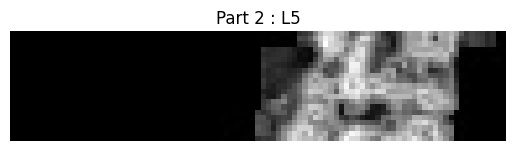

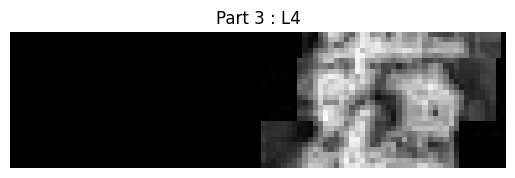

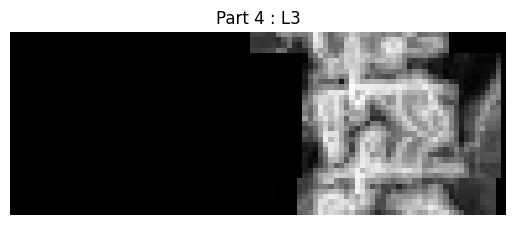

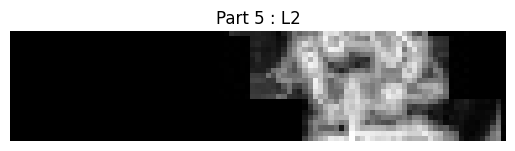

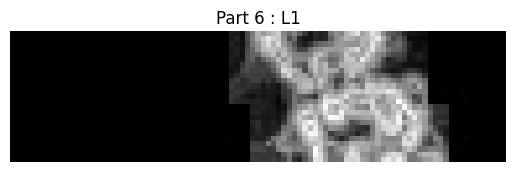

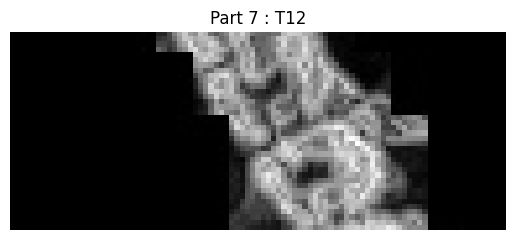

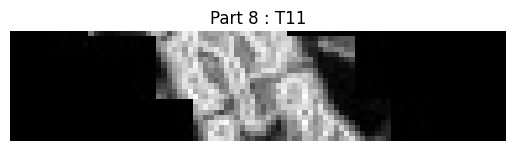

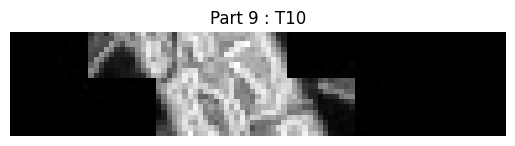

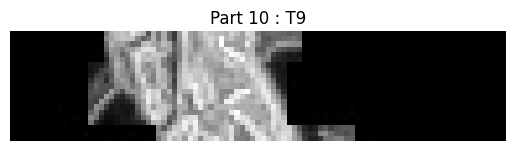

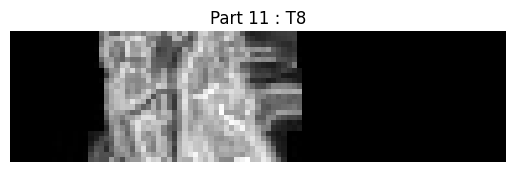

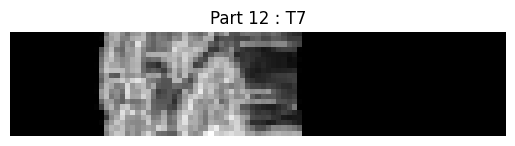

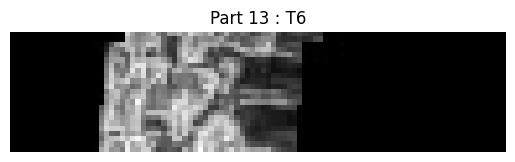

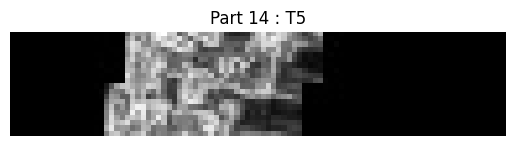

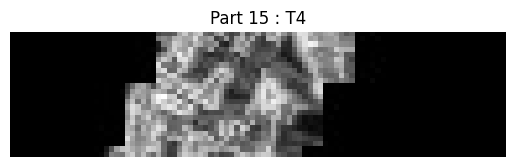

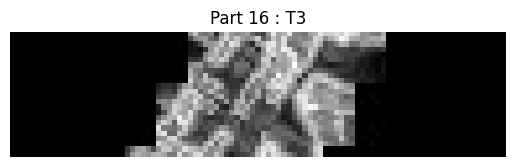

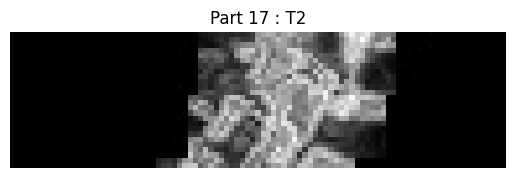

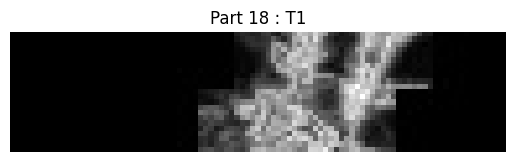

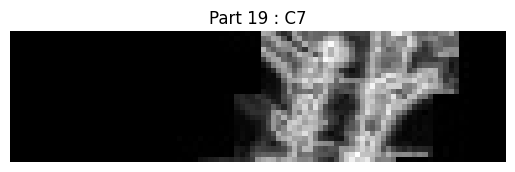

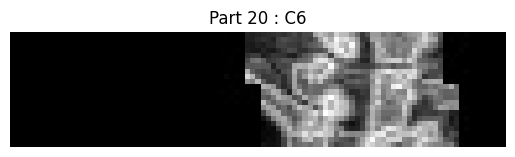

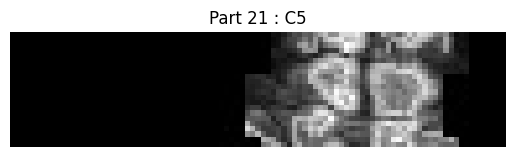

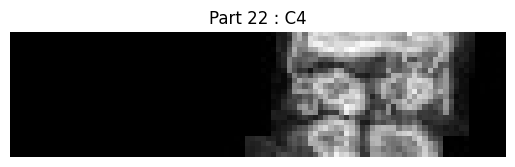

In [ ]:
import os
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Function to find the positions where the image should be cut
def calculate_crop_positions(image, scale_factor=2.5):
    width, height = image.size
    new_width = width // scale_factor
    left = (width - new_width) // 2  # Start from the horizontal center
    right = left + new_width  # Right edge of the crop
    return left, right, height

# Function to save the parts into a folder
def save_parts(parts, output_folder):
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)

    for idx, part in enumerate(parts):
        cv2.imwrite(f'{output_folder}/part_{idx+1}_{labels[idx]}.jpeg', part)
        plt.imshow(part, cmap='gray')
        plt.axis('off')  # Hide the axes
        plt.title(f'Part {idx+1} : {labels[idx]}')
        plt.show()

# Main function to process the image
def process_image(image_path, output_folder, local_min_indices, labels):
    # Load the image
    image = Image.open(image_path)
    left, right, height = calculate_crop_positions(image)

    modified_parts = []
    pre = 0

    # Cut the image and pick the brightest part of each piece
    for i in range(len(local_min_indices) - 1):
        top_0 = local_min_indices[i + 1]
        bottom_0 = local_min_indices[pre]

        if abs(top_0 - bottom_0) < height / 40:
            continue
        pre = i + 1

        # Cut the wanted part of the image
        top = max(0, top_0 - int(height / 50))
        bottom = min(height ,bottom_0 + int(height / 50))
        part = image.crop((left, top, right, bottom))

        # Convert the image to a numpy array
        part_array = np.array(part)

        modified_parts.append(part_array)

    # Save the cropped parts and display them
    save_parts(modified_parts, output_folder)

    return modified_parts

# Input variables
image_path = "/content/Spine_Segments.jpeg"
output_folder = "spine_parts"
local_min_indices = cut_points[::-1]
labels = ['Sacrum', 'L5', 'L4', 'L3', 'L2', 'L1', 'T12', 'T11', 'T10', 'T9', 'T8', 'T7', 'T6', 'T5', 'T4', 'T3', 'T2', 'T1', 'C7', 'C6', 'C5', 'C4', 'C3', 'C2', 'C1']

# Call the main function to process the image
modified_parts = process_image(image_path, output_folder, local_min_indices, labels)
